In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("..")

import jlinops

from rsolvers import RIASGKS

# Toy problem

In [6]:
ground_truth = jlinops.piecewise_constant_1d_test_problem()
n = len(ground_truth)
np.random.seed(0)
noise_stdev = 0.1
noise_var = noise_stdev**2
A = jlinops.Gaussian1DBlurOperator(n, blur_sigma=10, mode="reflect")
#A = jlinops.IdentityOperator((n,n))
noisy_signal = A.matvec(ground_truth) + noise_stdev*np.random.normal(size=n)
grid = np.arange(n)

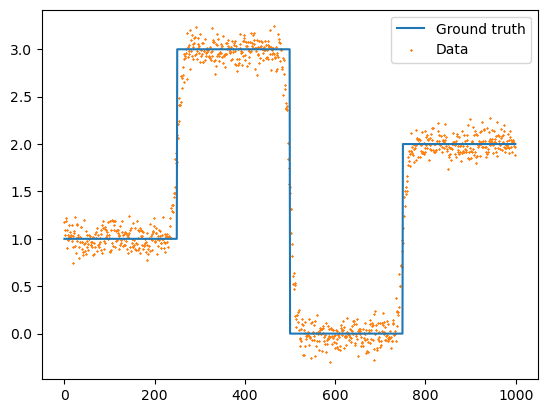

In [7]:
plt.plot(grid, ground_truth, label="Ground truth", color="C0")
plt.scatter(grid, noisy_signal, marker="x", label="Data", color="C1", alpha=1.0, s=0.5)
plt.legend()
plt.show()

# Define regularization

In [8]:
Lmat, Wmat = jlinops.first_order_derivative_1d(n, boundary="none")
L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator

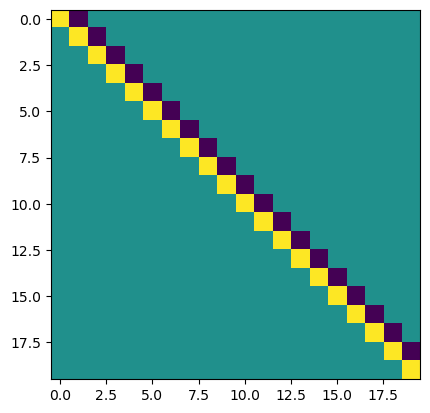

In [9]:
plt.imshow(Lmat.toarray()[:20,:20])
plt.show()

# Set up methods for comparison (first do convex case)

In [10]:
# TRIPs-Py methods are dp and gcv. The rest I have added. I believe dp is the same as dp3, except uses the GSVD in the formulation of the method whereas dp3 avoids using a GSVD.
methods = ["dp", "dp2", "dp3", "mgcv", "gcv", "matlab_gcv", "mgcv_no_whitening", "gcv_no_whitening", "matlab_gcv_no_whitening" ]
print(f"Number of methods to compare: {len(methods)}")

Number of methods to compare: 9


In [11]:
# Set problem parameters
n_iters = 1000
hyperpr_r = 1
hyperpr_beta = 1.5 + 1e-3
kmin = 5
kmax = 15

# Build a dictionary containg solvers and solver results
comp_dct = {}

# Iterate over methods
for method in methods:
    print(f"Started method: {method}")

    # Build solver
    if (method == "mgcv_no_whitening") or (method == "gcv_no_whitening") or (method == "matlab_gcv_no_whitening"):
        gksias_solver = RIASGKS(A, L, noisy_signal, noise_var=None)
    else:
        gksias_solver = RIASGKS(A, L, noisy_signal, noise_var=noise_var)

    # Processing for regparam method
    if (method == "mgcv_no_whitening"):
        regparam = "mgcv"
    elif (method == "gcv_no_whitening"):
        regparam = "gcv"
    elif (method == "matlab_gcv_no_whitening"):
        regparam = "matlab_gcv"
    else:
        regparam = method


    # Run the solver
    data = gksias_solver.solve(n_iter=n_iters, kmin=kmin, kmax=kmax, hyperpr_r=hyperpr_r, hyperpr_beta=hyperpr_beta, x_true=ground_truth, regparam=regparam)

    # Put results into dict
    comp_dct[method] = data

Started method: dp


Started method: dp2


Started method: dp3


 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value


/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/comparisons/../regparam_selection.py:298: RuntimeWarning: invalid value encountered in sqrt
  xbeta, _, _, _ = np.linalg.lstsq( np.vstack([ A, np.sqrt(1.0/beta)*L ]), np.hstack([ b, np.zeros(L.shape[0]) ]) , rcond=None  )


...

Started method: gcv


Started method: matlab_gcv


Started method: mgcv_no_whitening


Started method: gcv_no_whitening


Started method: matlab_gcv_no_whitening


# Comparison plots

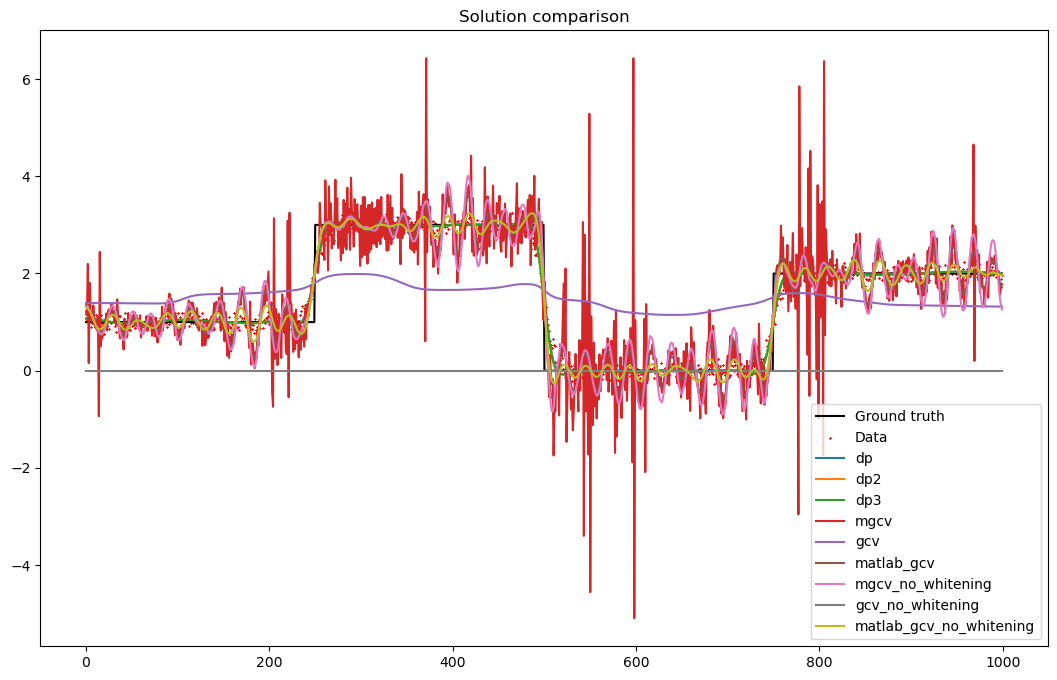

In [12]:
plt.figure(figsize=(13,8))

plt.plot(grid, ground_truth, label="Ground truth", color="black")
plt.scatter(grid, noisy_signal, marker="x", label="Data", color="red", alpha=1.0, s=0.5)

for method in comp_dct.keys():
    data = comp_dct[method]
    plt.plot(grid, data["x"], label=method)

plt.legend(loc="lower right")
plt.title("Solution comparison")
plt.show()

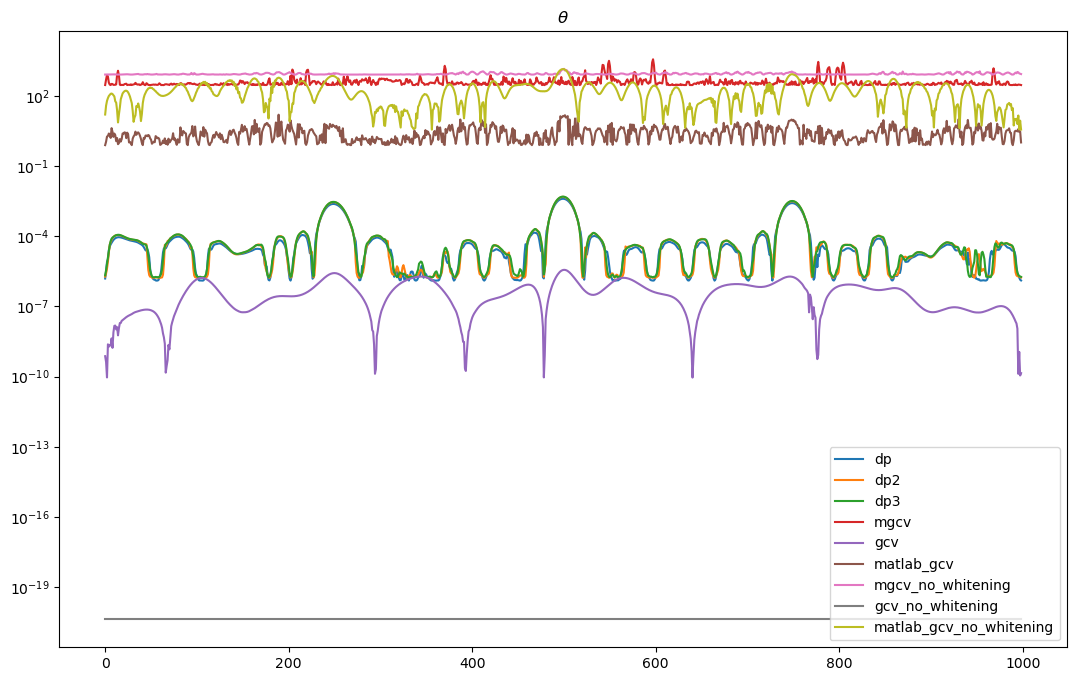

In [13]:
plt.figure(figsize=(13,8))


for method in comp_dct.keys():
    data = comp_dct[method]
    plt.semilogy(grid[:-1], data["theta"], label=method)

plt.legend(loc="lower right")
plt.title("$\\theta$")
plt.show()

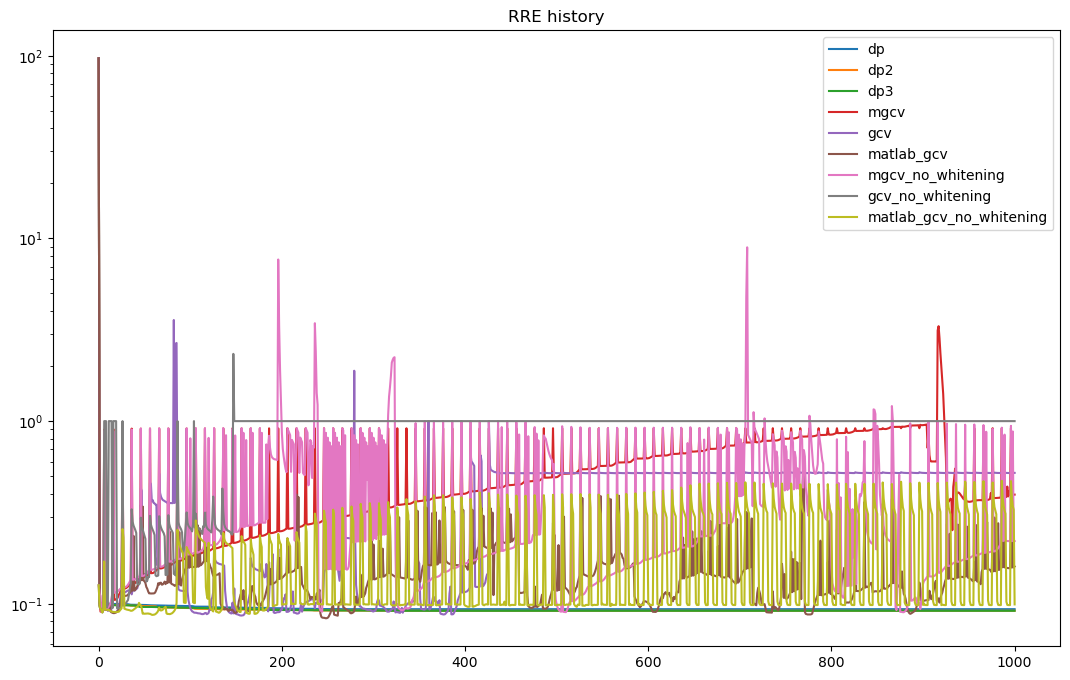

In [14]:
plt.figure(figsize=(13,8))


for method in comp_dct.keys():
    data = comp_dct[method]
    plt.semilogy(data["rre_history"], label=method)

plt.legend(loc="upper right")
plt.title("RRE history")
plt.show()

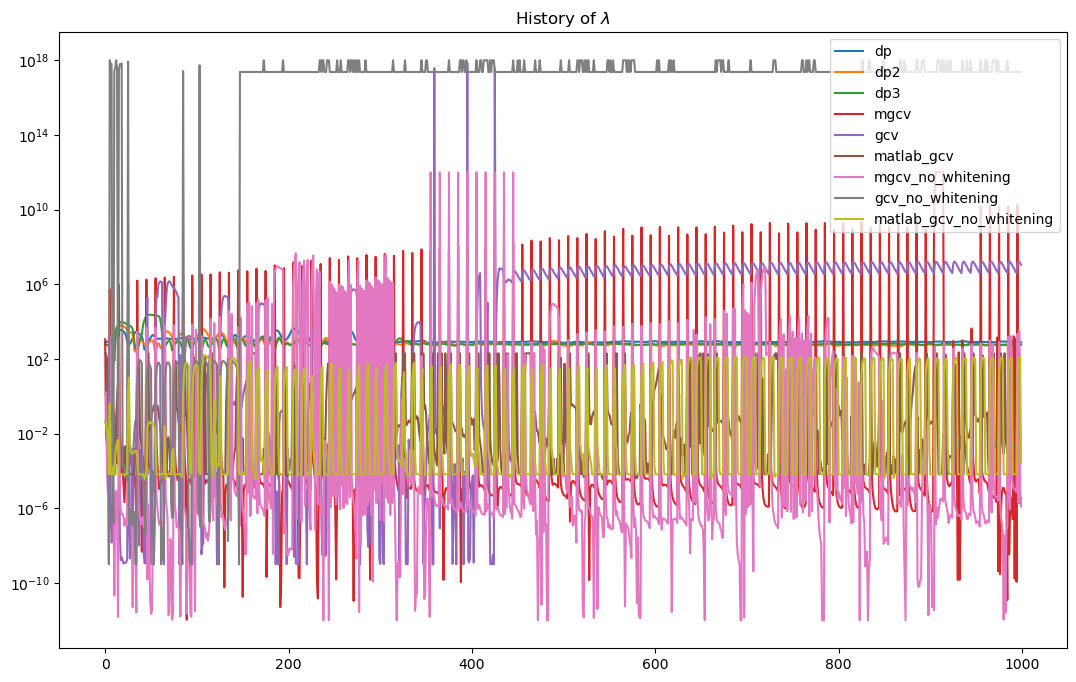

In [15]:
plt.figure(figsize=(13,8))

for method in comp_dct.keys():
    data = comp_dct[method]
    plt.semilogy(data["lambda_history"], label=method)

plt.legend(loc="upper right")
plt.title("History of $\\lambda$")
plt.show()

# Also do a nonconvex prior?

In [16]:
# Set problem parameters
n_iters = 1000
hyperpr_r = -1
hyperpr_beta = 1.0
kmin = 5
kmax = 15

# Build a dictionary containg solvers and solver results
comp_dct = {}

# Iterate over methods
for method in methods:
    print(f"Started method: {method}")

    # Build solver
    if (method == "mgcv_no_whitening") or (method == "gcv_no_whitening") or (method == "matlab_gcv_no_whitening"):
        gksias_solver = RIASGKS(A, L, noisy_signal, noise_var=None)
    else:
        gksias_solver = RIASGKS(A, L, noisy_signal, noise_var=noise_var)

    # Processing for regparam method
    if (method == "mgcv_no_whitening"):
        regparam = "mgcv"
    elif (method == "gcv_no_whitening"):
        regparam = "gcv"
    elif (method == "matlab_gcv_no_whitening"):
        regparam = "matlab_gcv"
    else:
        regparam = method

    try:
        # Run the solver
        data = gksias_solver.solve(n_iter=n_iters, kmin=kmin, kmax=kmax, hyperpr_r=hyperpr_r, hyperpr_beta=hyperpr_beta, x_true=ground_truth, regparam=regparam)
    except:
        print(f"failed for method = {method}")

    # Put results into dict
    comp_dct[method] = data

Started method: dp


Started method: dp2


 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value


/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/comparisons/../regparam_selection.py:170: RuntimeWarning: invalid value encountered in sqrt
  xbeta, _, _, _ = np.linalg.lstsq( np.vstack([ A, np.sqrt(1.0/beta)*L ]), np.hstack([ b, np.zeros(L.shape[0]) ]) , rcond=None  )


 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number 

...

Started method: gcv


Started method: matlab_gcv


Started method: mgcv_no_whitening


Started method: gcv_no_whitening


Started method: matlab_gcv_no_whitening


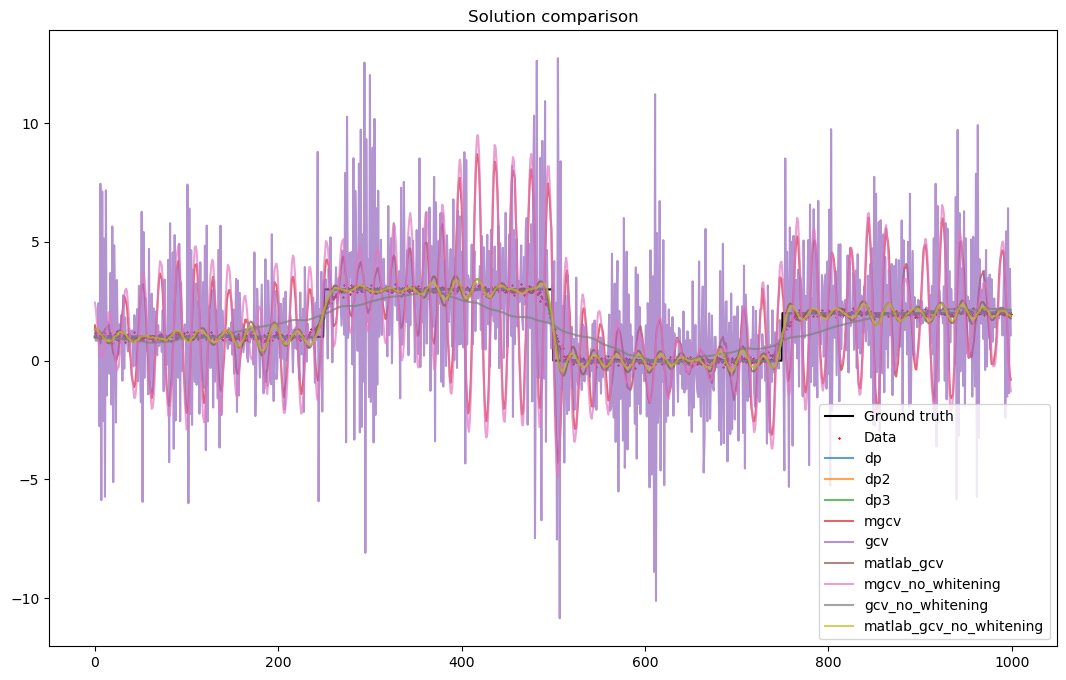

In [25]:
plt.figure(figsize=(13,8))

plt.plot(grid, ground_truth, label="Ground truth", color="black")
plt.scatter(grid, noisy_signal, marker="x", label="Data", color="red", alpha=1.0, s=0.5)

for method in comp_dct.keys():
    data = comp_dct[method]
    plt.plot(grid, data["x"], label=method, alpha=0.7)

plt.legend(loc="lower right")
plt.title("Solution comparison")
plt.show()

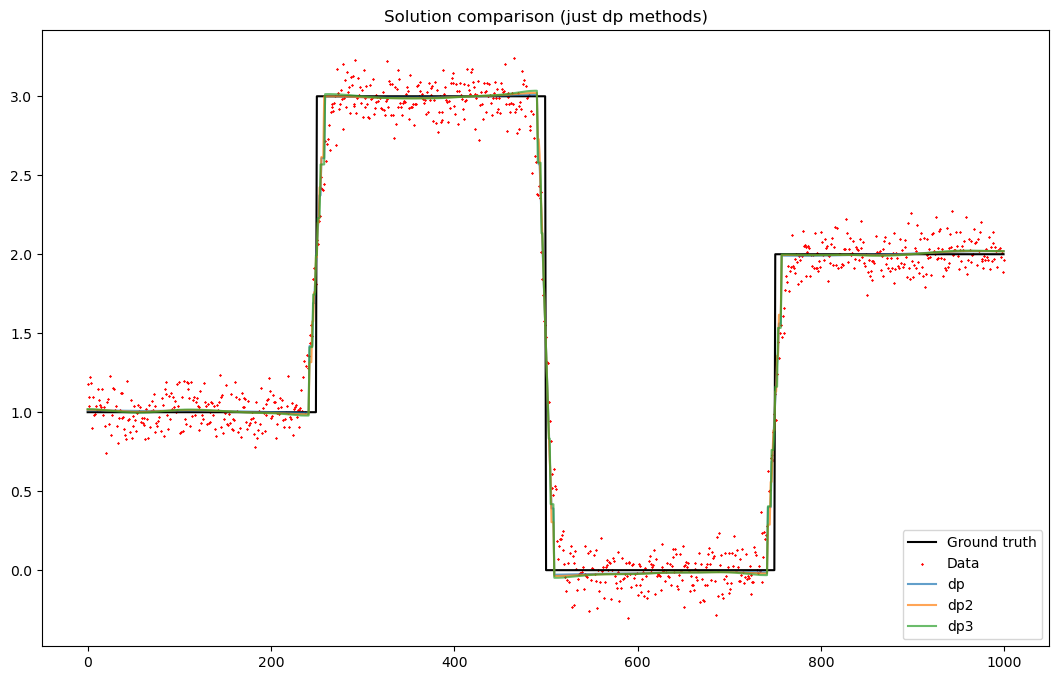

In [27]:
# Just dp?
plt.figure(figsize=(13,8))

plt.plot(grid, ground_truth, label="Ground truth", color="black")
plt.scatter(grid, noisy_signal, marker="x", label="Data", color="red", alpha=1.0, s=0.5)

for method in comp_dct.keys():
    if method[:2] == "dp":
        data = comp_dct[method]
        plt.plot(grid, data["x"], label=method, alpha=0.7)

plt.legend(loc="lower right")
plt.title("Solution comparison (just dp methods)")
plt.show()

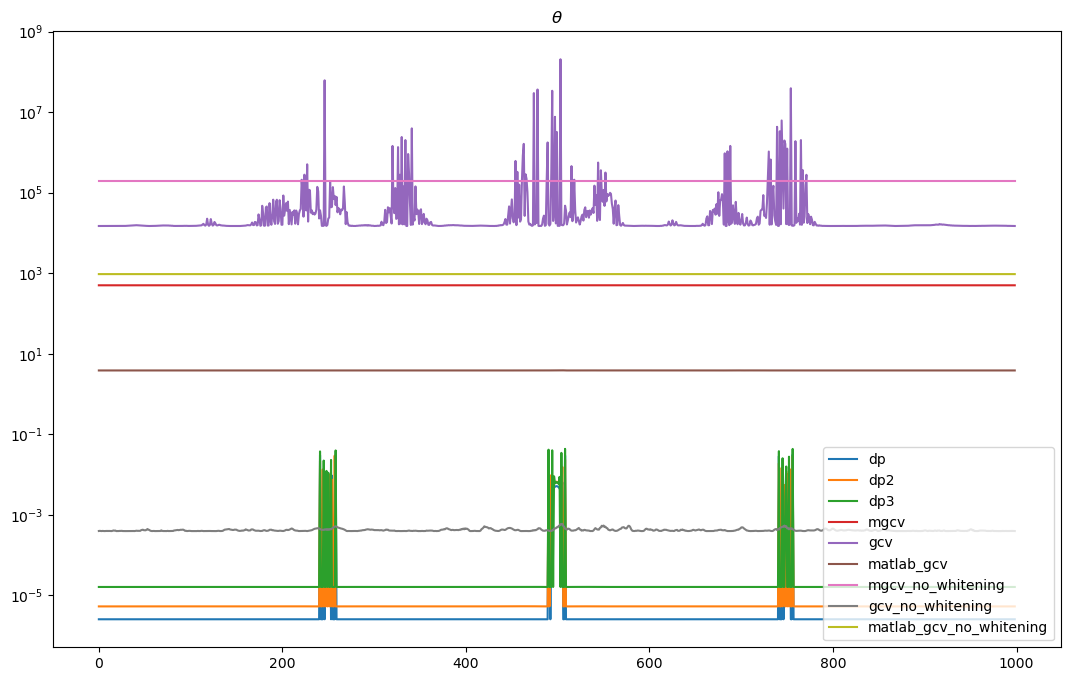

In [18]:
plt.figure(figsize=(13,8))


for method in comp_dct.keys():
    data = comp_dct[method]
    plt.semilogy(grid[:-1], data["theta"], label=method)

plt.legend(loc="lower right")
plt.title("$\\theta$")
plt.show()

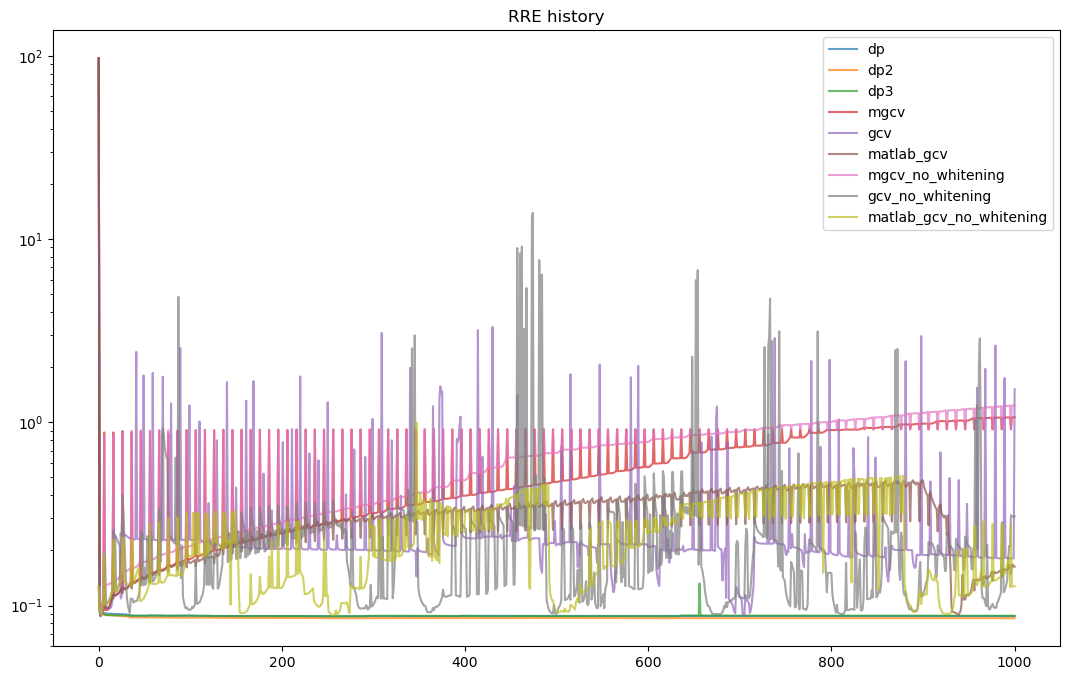

In [24]:
plt.figure(figsize=(13,8))


for method in comp_dct.keys():
    data = comp_dct[method]
    plt.semilogy(data["rre_history"], label=method, alpha=0.7)

plt.legend(loc="upper right")
plt.title("RRE history")
plt.show()

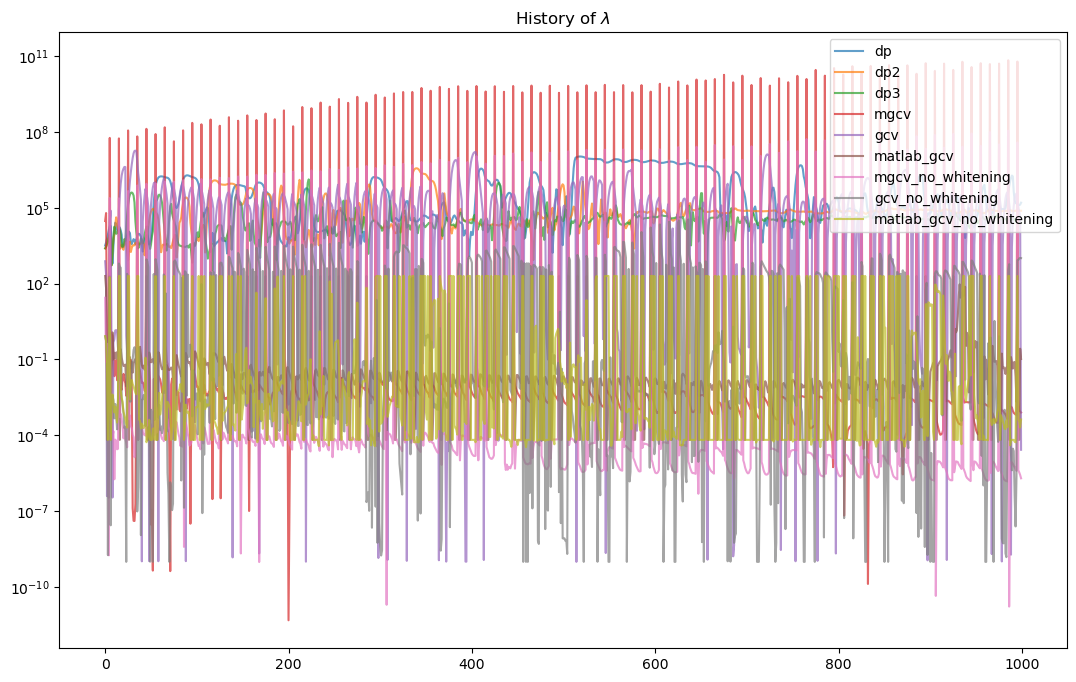

In [23]:
plt.figure(figsize=(13,8))

for method in comp_dct.keys():
    data = comp_dct[method]
    plt.semilogy(data["lambda_history"], label=method, alpha=0.7)

plt.legend(loc="upper right")
plt.title("History of $\\lambda$")
plt.show()